In [1]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer

import pandas as pd
df = pd.read_csv('steam_reviews_preprocessed.csv')
df = df.dropna().reset_index().drop(columns=['index'])
df_pre = df['prepro']
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df_pre)
df_FE = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())

# **Unsupervised: KMeans**

In [4]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from wordcloud import WordCloud

In [5]:
k = range(1,7)
inertia = []

for i in k:
    km_model = KMeans(n_clusters=i, random_state=10) # jumlah cluster akan di looping
    km_model.fit(df_FE)
    inertia.append(km_model.inertia_)

print(list(k))
print(inertia)

[1, 2, 3, 4, 5, 6]
[345.7091266828323, 336.98646601263647, 331.3563912507413, 326.71830088347684, 322.02961109043326, 308.58178055188154]


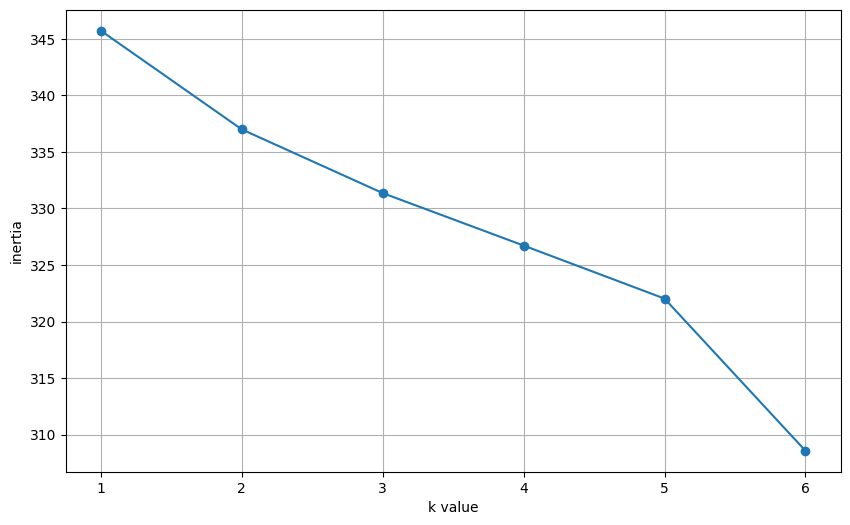

In [6]:
plt.figure(figsize=(10,6))
plt.plot(k, inertia, marker='o')
plt.xlabel('k value')
plt.ylabel('inertia')
plt.grid()
plt.show()

In [7]:
n_clusters = 4

In [9]:
kM = KMeans(n_clusters=n_clusters, random_state=10).fit(df_FE)
kM

KMeans(n_clusters=4, random_state=10)

In [10]:
df['Kmeans_label'] = kM.labels_
df.head()

,Reviews,Voted_up,rm_html,rm_hashtag,lower_case,rm_url,rm_punc,rm_emoji,stem,prepro,Kmeans_label
0,if you're looking for cozy game like harverst ...,True,if you're looking for cozy game like harverst ...,if you're looking for cozy game like harverst ...,if you're looking for cozy game like harverst ...,if you're looking for cozy game like harverst ...,if you re looking for cozy game like harverst ...,if you re looking for cozy game like harverst ...,if you re looking for cozy game like harverst ...,if you re looking for cozy game like harverst ...,3
1,Seru banget,True,Seru banget,Seru banget,seru banget,seru banget,seru banget,seru banget,seru banget,seru banget,1
2,game bagus,True,game bagus,game bagus,game bagus,game bagus,game bagus,game bagus,game bagus,game bagus,0
3,candu,True,candu,candu,candu,candu,candu,candu,candu,candu,3
4,asik,True,asik,asik,asik,asik,asik,asik,asik,asik,3


**Silhouette Score**

In [11]:
from sklearn import metrics
labels = kM.labels_
metrics.silhouette_score(df_FE, labels, metric='euclidean')

np.float64(0.024569492529027334)

**Word Cloud**

Kmeans for cluster 0


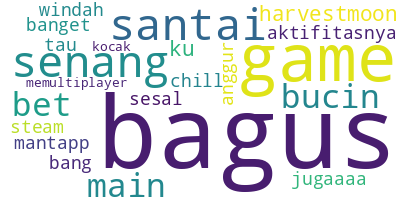

In [12]:
c = 0
print('Kmeans for cluster '+str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 1


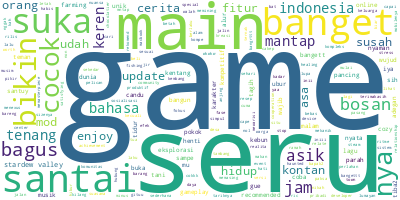

In [13]:
c = 1
print('Kmeans for cluster '+str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 2


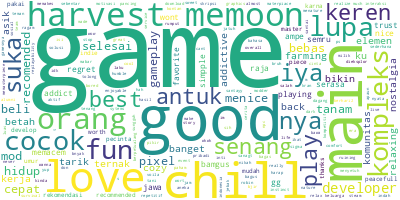

In [14]:
c = 2
print('Kmeans for cluster '+str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 3


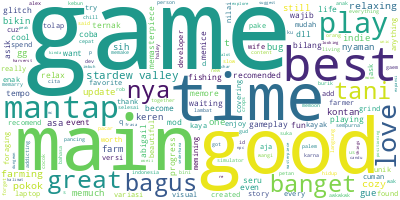

In [15]:
c = 3
print('Kmeans for cluster '+str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

# **Unsupervised: Hierarchical**

In [16]:
from scipy.cluster.hierarchy import dendrogram, linkage

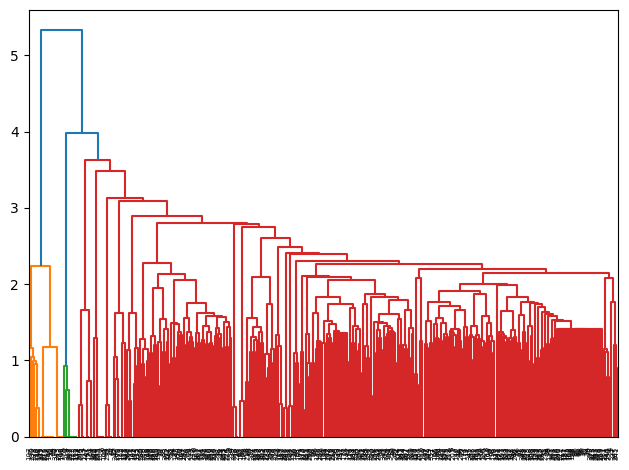

In [17]:
linkage_data = linkage(df_FE, method = 'ward', metric = 'euclidean')
dendrogram(linkage_data)
plt.tight_layout()
plt.show()

In [18]:
from sklearn.cluster import AgglomerativeClustering
hierarchical_cluster = AgglomerativeClustering(n_clusters = n_clusters, linkage = 'ward')
labels = hierarchical_cluster.fit(df_FE)

pred_agc = pd.Series(hierarchical_cluster.labels_)
df['Ward_label'] = pred_agc

In [19]:
df.head()

,Reviews,Voted_up,rm_html,rm_hashtag,lower_case,rm_url,rm_punc,rm_emoji,stem,prepro,Kmeans_label,Ward_label
0,if you're looking for cozy game like harverst ...,True,if you're looking for cozy game like harverst ...,if you're looking for cozy game like harverst ...,if you're looking for cozy game like harverst ...,if you're looking for cozy game like harverst ...,if you re looking for cozy game like harverst ...,if you re looking for cozy game like harverst ...,if you re looking for cozy game like harverst ...,if you re looking for cozy game like harverst ...,3,0
1,Seru banget,True,Seru banget,Seru banget,seru banget,seru banget,seru banget,seru banget,seru banget,seru banget,1,3
2,game bagus,True,game bagus,game bagus,game bagus,game bagus,game bagus,game bagus,game bagus,game bagus,0,2
3,candu,True,candu,candu,candu,candu,candu,candu,candu,candu,3,0
4,asik,True,asik,asik,asik,asik,asik,asik,asik,asik,3,0


**Silhouette Score**

In [20]:
from sklearn import metrics
labels = pred_agc
metrics.silhouette_score(df_FE, labels, metric='euclidean')

np.float64(0.044674871047096706)

**Word Cloud**

Hierarchical for cluster 0


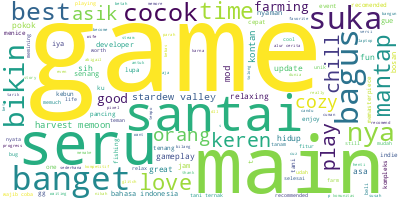

In [21]:
c = 0
print('Hierarchical for cluster '+str(c))
df_c = df[df['Ward_label'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

# **Supervised: Sentiment Analysis**

In [22]:
df['Sentiment'] = df['Voted_up'].map({True: 'positive', False: 'negative'})

Sentiment positive


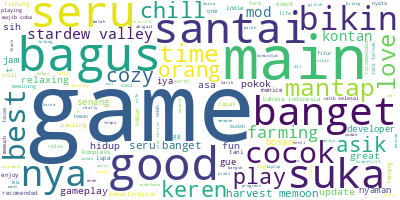

In [23]:
from wordcloud import WordCloud
c = 'positive'
print('Sentiment '+str(c))
df_c = df[df['Sentiment'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string); wordcloud.to_image()

Sentiment negative


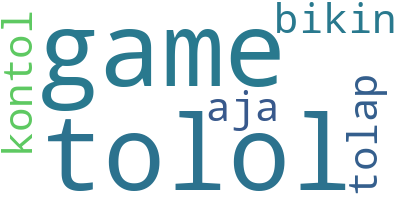

In [24]:
from wordcloud import WordCloud
c = 'negative'
print('Sentiment '+str(c))
df_c = df[df['Sentiment'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string); wordcloud.to_image()

In [25]:
import pandas as pd
df = pd.read_csv('steam_reviews_preprocessed.csv')
df = df.dropna().reset_index().drop(columns=['index'])
df_pre = df['prepro']

# Mengubah teks menjadi matriks TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer()
vecs = vectorizer.fit_transform(df_pre)
vecs

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 2194 stored elements and shape (356, 966)>

In [26]:
df['Sentiment'] = df['Voted_up'].map({True: 'positive', False: 'negative'})

# Classify
X = vecs # FE result
y = df['Sentiment']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

model = RandomForestClassifier()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[107]]
              precision    recall  f1-score   support

    positive       1.00      1.00      1.00       107

    accuracy                           1.00       107
   macro avg       1.00      1.00      1.00       107
weighted avg       1.00      1.00      1.00       107



In [27]:
testing = "game nya seru banget, grafiknya bagus dan ceritanya bikin nagih"
testing = vectorizer.transform([testing])
testing = model.predict(testing)
print(testing)

['positive']
